---
## 1. Import Libraries

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')

---
## 2. Load & Inspect Dataset

In [4]:
# Load Data
df_raw = pd.read_csv('EURUSD_M15.csv', sep='\t')

# Perbaiki nama kolom (header shift karena datetime menjadi index bawaan)
df_raw.rename(
    columns={
        'Time':   'Open',
        'Open':   'High',
        'High':   'Low',
        'Low':    'Close',
        'Close':  'Volume',
        'Volume': 'Spread'
    },
    inplace=True
)
df_raw.index = pd.to_datetime(df_raw.index)
df_raw.index.name = 'Datetime'

print("Shape dataset:", df_raw.shape)
print(f"Rentang waktu : {df_raw.index[0]}  →  {df_raw.index[-1]}")
print(f"Interval      : 15 menit")
print()
df_raw.head(5)

Shape dataset: (100000, 6)
Rentang waktu : 2021-09-10 20:15:00  →  2025-09-12 20:45:00
Interval      : 15 menit



,Open,High,Low,Close,Volume,Spread
Datetime,,,,,,
2021-09-10 20:15:00,1.18123,1.18127,1.18111,1.18117,284,3
2021-09-10 20:30:00,1.18117,1.18125,1.18098,1.18103,277,4
2021-09-10 20:45:00,1.18104,1.18121,1.18092,1.18101,1827,5
2021-09-12 21:00:00,1.18111,1.18147,1.18110,1.18139,57,66
2021-09-12 21:15:00,1.18139,1.18145,1.18132,1.18143,201,20


In [5]:
df_raw.info()
print()
df_raw[['Open','High','Low','Close']].describe().round(6)

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 100000 entries, 2021-09-10 20:15:00 to 2025-09-12 20:45:00
Data columns (total 6 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Open    100000 non-null  float64
 1   High    100000 non-null  float64
 2   Low     100000 non-null  float64
 3   Close   100000 non-null  float64
 4   Volume  100000 non-null  int64  
 5   Spread  100000 non-null  int64  
dtypes: float64(4), int64(2)
memory usage: 5.3 MB



,Open,High,Low,Close
count,100000.000000,100000.000000,100000.000000,100000.000000
mean,1.085727,1.086080,1.085373,1.085726
std,0.044390,0.044351,0.044427,0.044390
min,0.953900,0.955170,0.953570,0.953900
25%,1.060040,1.060470,1.059640,1.060040
50%,1.084550,1.084840,1.084280,1.084555
75%,1.111090,1.111440,1.110742,1.111080
max,1.184150,1.184580,1.183860,1.184140


In [6]:
# Cek missing values
missing = df_raw[['Open','High','Low','Close']].isnull().sum()
print(missing)

Open     0
High     0
Low      0
Close    0
dtype: int64


---
## 3. Exploratory Data Analysis (EDA)

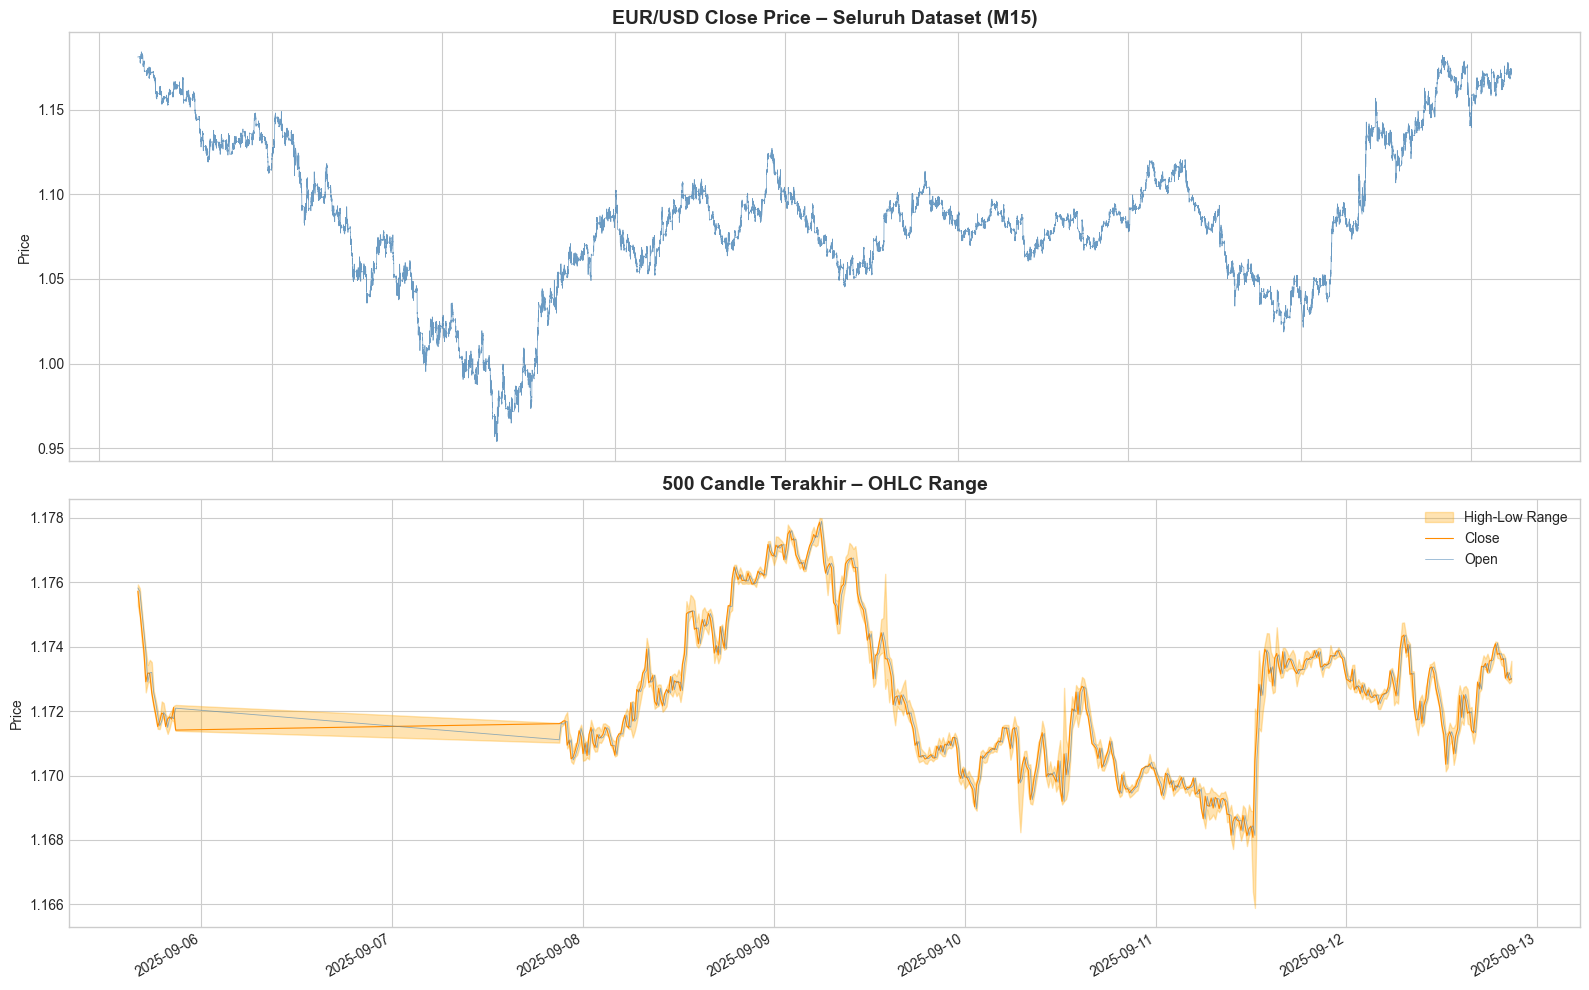

In [7]:
#  Harga Close Keseluruhan
fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# Close price seluruh dataset
axes[0].plot(df_raw.index, df_raw['Close'], color='steelblue', linewidth=0.5, alpha=0.8)
axes[0].set_title('EUR/USD Close Price – Seluruh Dataset (M15)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Price')
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
axes[0].xaxis.set_major_locator(mdates.MonthLocator(interval=6))
fig.autofmt_xdate()

# Sample 500 candle terakhir
sample = df_raw[['Open','High','Low','Close']].tail(500)
axes[1].fill_between(sample.index, sample['Low'], sample['High'], alpha=0.3, color='orange', label='High-Low Range')
axes[1].plot(sample.index, sample['Close'], color='darkorange', linewidth=0.8, label='Close')
axes[1].plot(sample.index, sample['Open'],  color='steelblue',  linewidth=0.6, alpha=0.6, label='Open')
axes[1].set_title('500 Candle Terakhir – OHLC Range', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Price')
axes[1].legend()

plt.tight_layout()
plt.show()

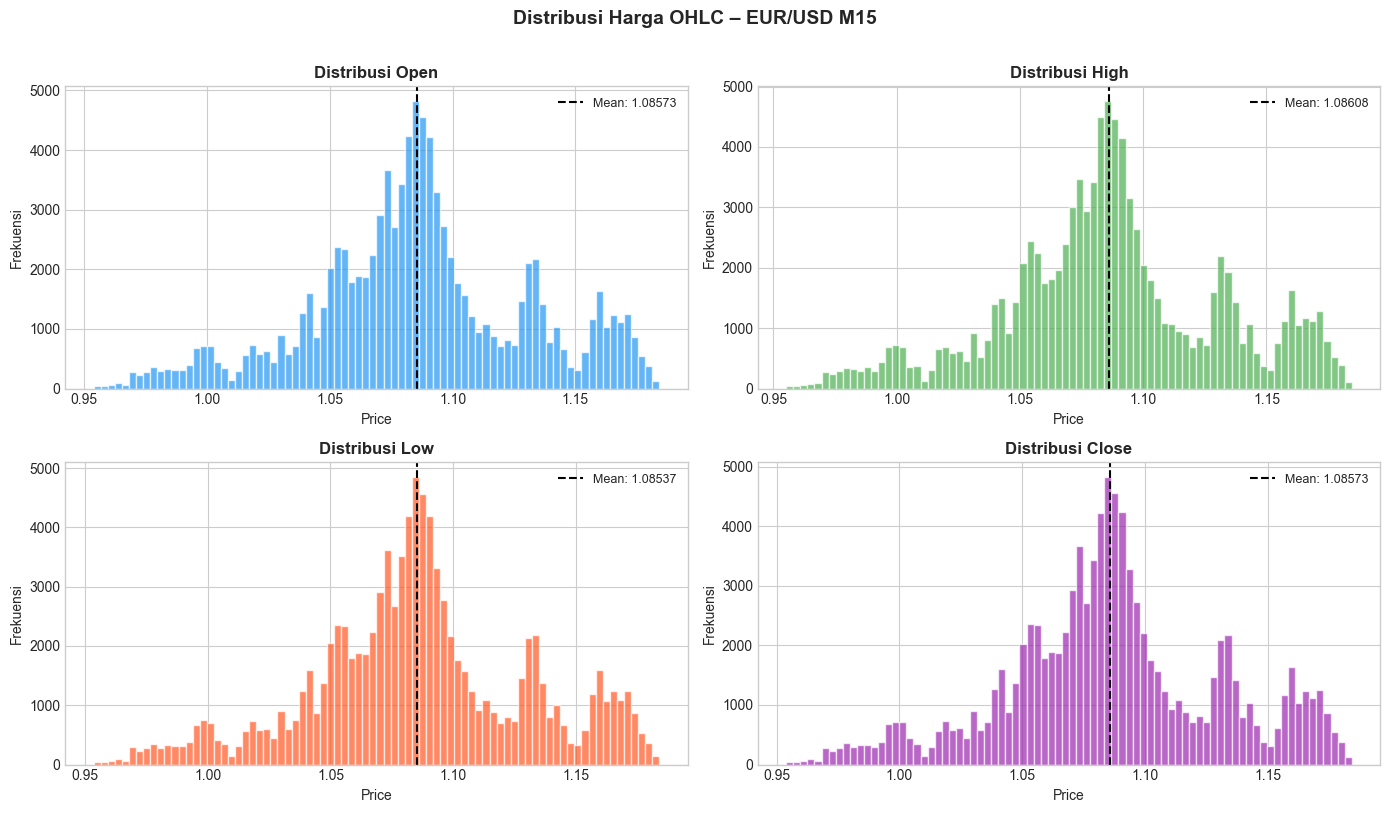

In [8]:
# Distribusi OHLC
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
cols = ['Open', 'High', 'Low', 'Close']
colors = ['#2196F3','#4CAF50','#FF5722','#9C27B0']

for ax, col, color in zip(axes.flatten(), cols, colors):
    ax.hist(df_raw[col], bins=80, color=color, alpha=0.7, edgecolor='white')
    ax.axvline(df_raw[col].mean(), color='black', linestyle='--', linewidth=1.5, label=f'Mean: {df_raw[col].mean():.5f}')
    ax.set_title(f'Distribusi {col}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Price')
    ax.set_ylabel('Frekuensi')
    ax.legend(fontsize=9)

plt.suptitle('Distribusi Harga OHLC – EUR/USD M15', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

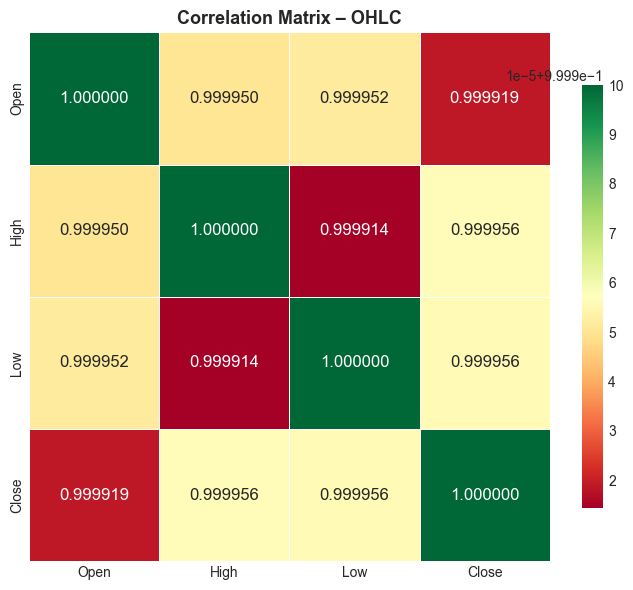

In [9]:
# Heatmap
corr = df_raw[['Open','High','Low','Close']].corr()

plt.figure(figsize=(7, 6))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr, annot=True, fmt='.6f', cmap='RdYlGn',
    linewidths=0.5, annot_kws={'size': 12},
    cbar_kws={'shrink': 0.8}
)
plt.title('Correlation Matrix – OHLC', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


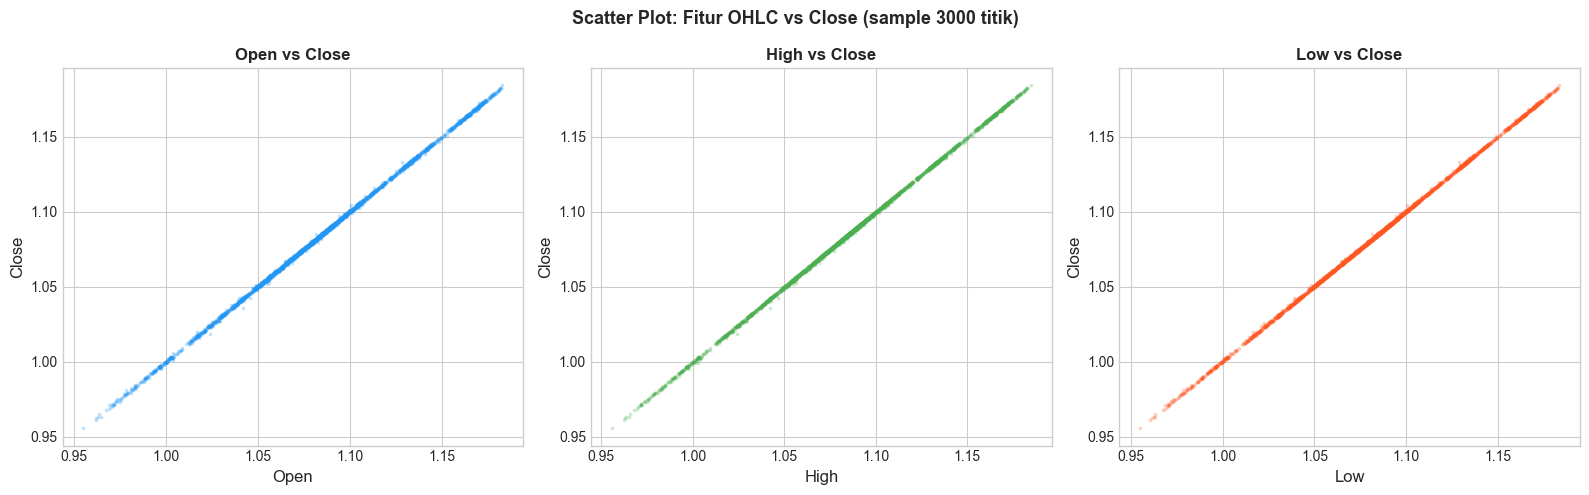

In [10]:
# Scatter Plot OHLC vs Close
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
features = ['Open', 'High', 'Low']
colors = ['#2196F3','#4CAF50','#FF5722']

sample_idx = np.random.choice(len(df_raw), 3000, replace=False)

for ax, feat, color in zip(axes, features, colors):
    ax.scatter(df_raw[feat].iloc[sample_idx], df_raw['Close'].iloc[sample_idx],
               alpha=0.2, s=3, color=color)
    ax.set_xlabel(feat, fontsize=12)
    ax.set_ylabel('Close', fontsize=12)
    ax.set_title(f'{feat} vs Close', fontsize=12, fontweight='bold')

plt.suptitle('Scatter Plot: Fitur OHLC vs Close (sample 3000 titik)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

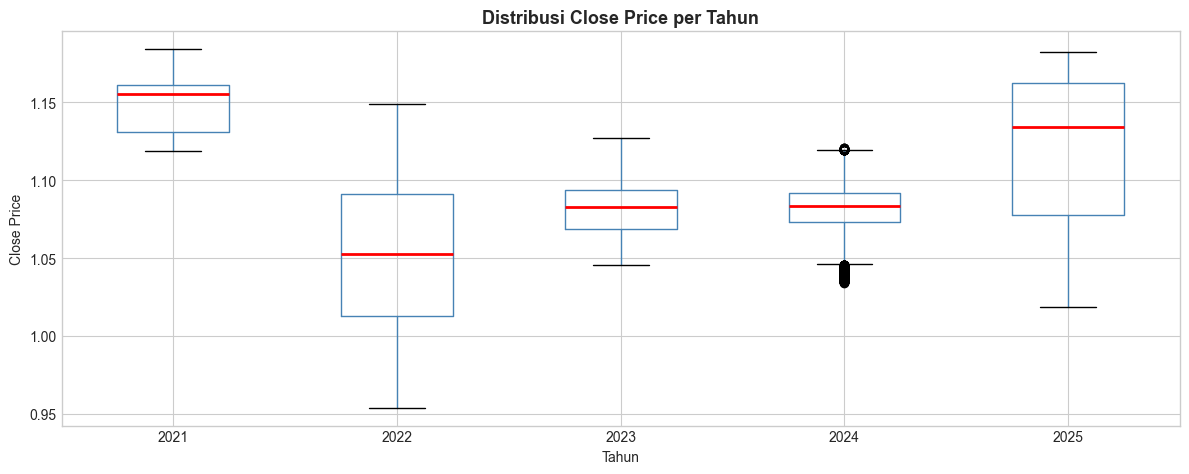

In [11]:
# Boxplot per Tahun
df_raw['Year'] = df_raw.index.year

plt.figure(figsize=(12, 5))
df_raw.boxplot(column='Close', by='Year', ax=plt.gca(),
               boxprops=dict(color='steelblue'),
               whiskerprops=dict(color='steelblue'),
               medianprops=dict(color='red', linewidth=2))
plt.title('Distribusi Close Price per Tahun', fontsize=13, fontweight='bold')
plt.suptitle('')
plt.xlabel('Tahun')
plt.ylabel('Close Price')
plt.tight_layout()
plt.show()

df_raw.drop(columns=['Year'], inplace=True)

---
## 4. Data Preprocessing

In [12]:
# Feature Engineering: Data Shifting

df = df_raw[['Open','High','Low','Close']].copy()

# Target = Close t+1 (shift -1)
df['Close_Next'] = df['Close'].shift(-1)

# Hapus baris terakhir (NaN akibat shift)
df.dropna(inplace=True)

print(f"Dataset setelah shifting: {df.shape}")
print("Fitur input  : Open, High, Low, Close  (waktu t)")
print("Target output: Close_Next              (waktu t+1)")
print()
df.head(5)

Dataset setelah shifting: (99999, 5)
Fitur input  : Open, High, Low, Close  (waktu t)
Target output: Close_Next              (waktu t+1)



,Open,High,Low,Close,Close_Next
Datetime,,,,,
2021-09-10 20:15:00,1.18123,1.18127,1.18111,1.18117,1.18103
2021-09-10 20:30:00,1.18117,1.18125,1.18098,1.18103,1.18101
2021-09-10 20:45:00,1.18104,1.18121,1.18092,1.18101,1.18139
2021-09-12 21:00:00,1.18111,1.18147,1.18110,1.18139,1.18143
2021-09-12 21:15:00,1.18139,1.18145,1.18132,1.18143,1.18141


In [13]:
# Train–Test Split (70/30)
split_idx = int(len(df) * 0.70)

train_df = df.iloc[:split_idx]
test_df  = df.iloc[split_idx:]

print(f"Total data    : {len(df):,}")
print(f"Training set  : {len(train_df):,} ({len(train_df)/len(df)*100:.1f}%)")
print(f"  Dari  : {train_df.index[0]}")
print(f"  Sampai: {train_df.index[-1]}")
print(f"Test set      : {len(test_df):,} ({len(test_df)/len(df)*100:.1f}%)")
print(f"  Dari  : {test_df.index[0]}")
print(f"  Sampai: {test_df.index[-1]}")

Total data    : 99,999
Training set  : 69,999 (70.0%)
  Dari  : 2021-09-10 20:15:00
  Sampai: 2024-07-01 17:15:00
Test set      : 30,000 (30.0%)
  Dari  : 2024-07-01 17:30:00
  Sampai: 2025-09-12 20:30:00


In [14]:
# Normalisasi

feature_cols = ['Open', 'High', 'Low', 'Close']

X_min = train_df[feature_cols].min()
X_max = train_df[feature_cols].max()

y_min = train_df['Close_Next'].min()
y_max = train_df['Close_Next'].max()

def minmax_scale(data, col_min, col_max):
    return (data - col_min) / (col_max - col_min)

def minmax_inverse(scaled, y_min, y_max):
    return scaled * (y_max - y_min) + y_min

X_train = minmax_scale(train_df[feature_cols], X_min, X_max).values
X_test  = minmax_scale(test_df[feature_cols],  X_min, X_max).values

y_train = minmax_scale(train_df['Close_Next'], y_min, y_max).values
y_test  = minmax_scale(test_df['Close_Next'],  y_min, y_max).values

y_test_actual  = test_df['Close_Next'].values
y_train_actual = train_df['Close_Next'].values

print("Normalisasi selesai (Min-Max, hanya dari training set).")
print(f"X_train shape: {X_train.shape}")
print(f"X_test  shape: {X_test.shape}")
print(f"y range       : [{y_train.min():.4f}, {y_train.max():.4f}] (normalized)")

Normalisasi selesai (Min-Max, hanya dari training set).
X_train shape: (69999, 4)
X_test  shape: (30000, 4)
y range       : [0.0000, 1.0000] (normalized)


---
## 5. Model Training – Multiple Linear Regression (Gradient Descent)

In [15]:
class MultipleLinearRegression:
    """
    Multiple Linear Regression dengan Gradient Descent.
    Model: y = w1*x1 + w2*x2 + w3*x3 + w4*x4 + b
    """
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.lr     = learning_rate
        self.n_iter = n_iterations
        self.weights = None
        self.bias    = None
        self.loss_history = []

    def fit(self, X, y, verbose=True, log_every=100):
        n_samples, n_features = X.shape
        # Inisialisasi bobot dan bias = 0
        self.weights = np.zeros(n_features)
        self.bias    = 0.0

        for i in range(1, self.n_iter + 1):
            # Forward pass
            y_pred = X @ self.weights + self.bias
            error  = y_pred - y

            # MSE loss
            loss = np.mean(error ** 2)
            self.loss_history.append(loss)

            # Gradients
            dw = (2 / n_samples) * (X.T @ error)
            db = (2 / n_samples) * np.sum(error)

            # Update
            self.weights -= self.lr * dw
            self.bias    -= self.lr * db

            if verbose and i % log_every == 0:
                print(f"  Iterasi {i:5d}/{self.n_iter}  |  MSE Loss: {loss:.8f}")

        return self

    def predict(self, X):
        return X @ self.weights + self.bias


print("Class MultipleLinearRegression berhasil didefinisikan.")

Class MultipleLinearRegression berhasil didefinisikan.


In [16]:
LEARNING_RATE = 0.1
N_ITERATIONS  = 1000

print(f"Mulai training...")
print(f"  Learning rate : {LEARNING_RATE}")
print(f"  Iterasi       : {N_ITERATIONS}")
print(f"  Jumlah fitur  : {X_train.shape[1]} (Open, High, Low, Close)")
print(f"  Data training : {X_train.shape[0]:,} sampel")
print()

model = MultipleLinearRegression(learning_rate=LEARNING_RATE, n_iterations=N_ITERATIONS)
model.fit(X_train, y_train, verbose=True, log_every=100)

print()
print("=" * 50)
print("Training selesai!")
print(f"  Bobot  (w) : {model.weights}")
print(f"  Bias   (b) : {model.bias:.8f}")
print(f"  Final Loss : {model.loss_history[-1]:.10f}")

Mulai training...
  Learning rate : 0.1
  Iterasi       : 1000
  Jumlah fitur  : 4 (Open, High, Low, Close)
  Data training : 69,999 sampel

  Iterasi   100/1000  |  MSE Loss: 0.00058715
  Iterasi   200/1000  |  MSE Loss: 0.00005839
  Iterasi   300/1000  |  MSE Loss: 0.00001190
  Iterasi   400/1000  |  MSE Loss: 0.00000781
  Iterasi   500/1000  |  MSE Loss: 0.00000745
  Iterasi   600/1000  |  MSE Loss: 0.00000742
  Iterasi   700/1000  |  MSE Loss: 0.00000742
  Iterasi   800/1000  |  MSE Loss: 0.00000742
  Iterasi   900/1000  |  MSE Loss: 0.00000742
  Iterasi  1000/1000  |  MSE Loss: 0.00000741

Training selesai!
  Bobot  (w) : [0.24927643 0.25006025 0.24985773 0.24983424]
  Bias   (b) : 0.00108391
  Final Loss : 0.0000074149


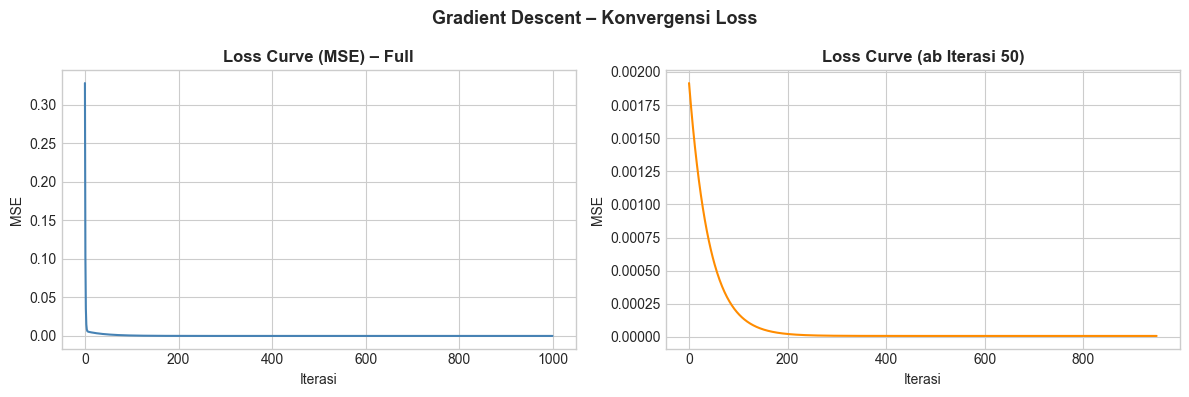

Loss awal  : 0.32823379
Loss akhir : 0.0000074149
Penurunan  : 100.00%


In [17]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(model.loss_history, color='steelblue', linewidth=1.5)
plt.title('Loss Curve (MSE) – Full', fontsize=12, fontweight='bold')
plt.xlabel('Iterasi')
plt.ylabel('MSE')

plt.subplot(1, 2, 2)
plt.plot(model.loss_history[50:], color='darkorange', linewidth=1.5)
plt.title('Loss Curve (ab Iterasi 50)', fontsize=12, fontweight='bold')
plt.xlabel('Iterasi')
plt.ylabel('MSE')

plt.suptitle('Gradient Descent – Konvergensi Loss', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Loss awal  : {model.loss_history[0]:.8f}")
print(f"Loss akhir : {model.loss_history[-1]:.10f}")
print(f"Penurunan  : {((model.loss_history[0] - model.loss_history[-1]) / model.loss_history[0] * 100):.2f}%")

In [18]:
# Prediksi pada Test Set
y_pred_scaled = model.predict(X_test)
y_pred_actual = minmax_inverse(y_pred_scaled, y_min, y_max)
y_pred_actual = np.clip(y_pred_actual, y_min, y_max)

print(f"Prediksi selesai pada {len(y_test):,} data test.")
print(f"Sample prediksi vs aktual (5 pertama):")
print(f"{'Actual':>12}  {'Predicted':>12}  {'Error':>12}")
for i in range(5):
    err = y_pred_actual[i] - y_test_actual[i]
    print(f"{y_test_actual[i]:12.5f}  {y_pred_actual[i]:12.5f}  {err:+12.5f}")

Prediksi selesai pada 30,000 data test.
Sample prediksi vs aktual (5 pertama):
      Actual     Predicted         Error
     1.07293       1.07319      +0.00026
     1.07268       1.07300      +0.00032
     1.07250       1.07280      +0.00030
     1.07288       1.07259      -0.00029
     1.07295       1.07268      -0.00027


---
## 6. Baseline – Naive Forecast

In [19]:
# Naive Forecast: prediksi = Close saat ini (Close t → prediksi Close t+1)
naive_pred = test_df['Close'].values  # Close t sebagai prediksi Close t+1

print(f"Baseline Naive Forecast: menggunakan Close[t] sebagai prediksi Close[t+1]")
print(f"Jumlah data : {len(naive_pred):,}")

Baseline Naive Forecast: menggunakan Close[t] sebagai prediksi Close[t+1]
Jumlah data : 30,000


---
## 7. Evaluasi & Perbandingan

In [20]:
def evaluate(y_true, y_pred, name="Model"):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)
    r2   = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    print(f"{'─'*40}")
    print(f"  [{name}]")
    print(f"  RMSE : {rmse:.6f}")
    print(f"  MAE  : {mae:.6f}")
    print(f"  R²   : {r2:.6f}")
    print(f"  MAPE : {mape:.4f}%")
    return {'Model': name, 'RMSE': rmse, 'MAE': mae, 'R2': r2, 'MAPE(%)': mape}

print("=" * 40)
print("HASIL EVALUASI – TEST SET")
mlr_metrics   = evaluate(y_test_actual, y_pred_actual, "MLR (Gradient Descent)")
naive_metrics = evaluate(y_test_actual, naive_pred,    "Naive Forecast (Baseline)")
print(f"{'─'*40}")

HASIL EVALUASI – TEST SET
────────────────────────────────────────
  [MLR (Gradient Descent)]
  RMSE : 0.000642
  MAE  : 0.000407
  R²   : 0.999794
  MAPE : 0.0369%
────────────────────────────────────────
  [Naive Forecast (Baseline)]
  RMSE : 0.000581
  MAE  : 0.000366
  R²   : 0.999831
  MAPE : 0.0332%
────────────────────────────────────────


In [21]:
# Tabel Perbandingan
results_df = pd.DataFrame([mlr_metrics, naive_metrics])
results_df = results_df.set_index('Model')
results_df = results_df.round(6)

print("\n=== TABEL PERBANDINGAN METRIK ===")
display(results_df)

# Analisis
print("\n=== ANALISIS ===")
for metric in ['RMSE','MAE','MAPE(%)']:
    mlr_val   = results_df.loc['MLR (Gradient Descent)', metric]
    naive_val = results_df.loc['Naive Forecast (Baseline)', metric]
    imprv     = (naive_val - mlr_val) / naive_val * 100
    status    = "✓ Lebih baik" if imprv > 0 else "✗ Lebih buruk"
    print(f"  {metric:8s}: MLR {mlr_val:.6f} vs Naive {naive_val:.6f}  →  {status} ({imprv:+.2f}%)")


=== TABEL PERBANDINGAN METRIK ===


,RMSE,MAE,R2,MAPE(%)
Model,,,,
MLR (Gradient Descent),0.000642,0.000407,0.999794,0.036925
Naive Forecast (Baseline),0.000581,0.000366,0.999831,0.033220



=== ANALISIS ===
  RMSE    : MLR 0.000642 vs Naive 0.000581  →  ✗ Lebih buruk (-10.50%)
  MAE     : MLR 0.000407 vs Naive 0.000366  →  ✗ Lebih buruk (-11.20%)
  MAPE(%) : MLR 0.036925 vs Naive 0.033220  →  ✗ Lebih buruk (-11.15%)


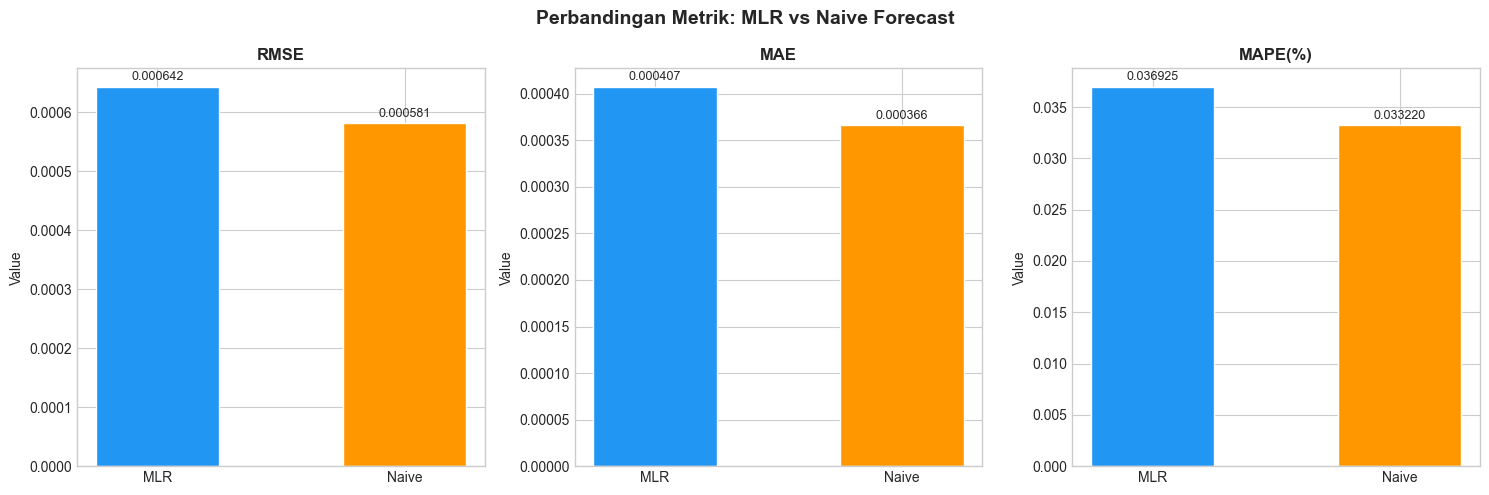

In [22]:
# Visualisasi Metrik
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
metrics_vis = ['RMSE', 'MAE', 'MAPE(%)']
colors_bar  = ['#2196F3', '#FF9800']

for ax, metric in zip(axes, metrics_vis):
    vals  = [results_df.loc['MLR (Gradient Descent)', metric],
             results_df.loc['Naive Forecast (Baseline)', metric]]
    bars  = ax.bar(['MLR', 'Naive'], vals, color=colors_bar, edgecolor='white', width=0.5)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() * 1.01,
                f'{val:.6f}', ha='center', va='bottom', fontsize=9)
    ax.set_title(metric, fontsize=12, fontweight='bold')
    ax.set_ylabel('Value')

plt.suptitle('Perbandingan Metrik: MLR vs Naive Forecast', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 8. Save Model


In [23]:
import pickle

# 1. Pastikan kolom target Close_Next ada (mengantisipasi KeyError)
if 'Close_Next' not in df_raw.columns:
    df_raw['Close_Next'] = df_raw['Close'].shift(-1)
    df_raw.dropna(inplace=True)

# 2. Ambil nilai batas MinMax sesuai dengan variabel dataframe df_raw kamu
X_min = df_raw[['Open', 'High', 'Low', 'Close']].min().values
X_max = df_raw[['Open', 'High', 'Low', 'Close']].max().values
y_min = df_raw['Close_Next'].min()
y_max = df_raw['Close_Next'].max()

# 3. Bungkus model utama Anda (Multiple Linear Regression) beserta parameter scaling
model_data = {
    'model': model,
    'X_min': X_min,
    'X_max': X_max,
    'y_min': y_min,
    'y_max': y_max
}

# 4. Simpan ke dalam file pkl
with open('mlr_eurusd_model.pkl', 'wb') as f:
    pickle.dump(model_data, f)

# Print baru yang lebih bersih dan informatif
print("=" * 60)
print(" STATUS EXPORT MODEL: BERHASIL SIMPAN ✅")
print("=" * 60)
print(f" File Target       : mlr_eurusd_model.pkl")
print(f" Jumlah Fitur (X)  : {len(X_min)} Kolom (Open, High, Low, Close)")
print(f" Rentang Target (y): {y_min:.5f} sampai {y_max:.5f}")
print("-" * 60)
print("Silakan download file .pkl tersebut dari panel kiri Google Colab!")

 STATUS EXPORT MODEL: BERHASIL SIMPAN ✅
 File Target       : mlr_eurusd_model.pkl
 Jumlah Fitur (X)  : 4 Kolom (Open, High, Low, Close)
 Rentang Target (y): 0.95390 sampai 1.18414
------------------------------------------------------------
Silakan download file .pkl tersebut dari panel kiri Google Colab!


---
## 9. Visualisasi Hasil Prediksi

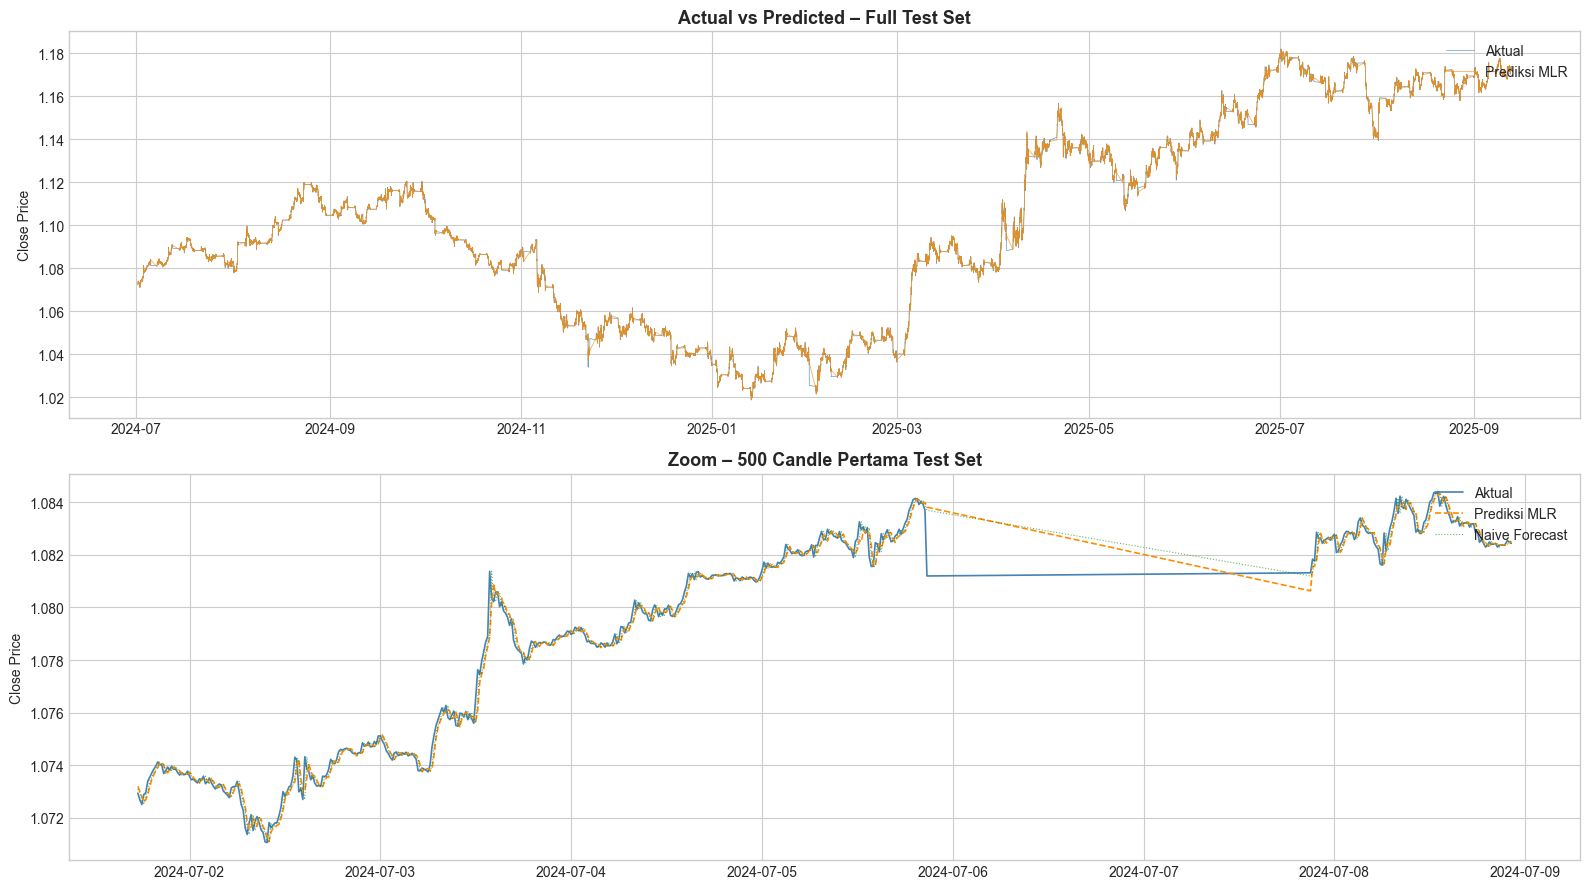

In [24]:
# Actual vs Predicted
fig, axes = plt.subplots(2, 1, figsize=(16, 9))

test_dates = test_df.index

# Plot atas: full test set
axes[0].plot(test_dates, y_test_actual, color='steelblue', linewidth=0.5, alpha=0.8, label='Aktual')
axes[0].plot(test_dates, y_pred_actual, color='darkorange', linewidth=0.5, alpha=0.8, label='Prediksi MLR')
axes[0].set_title('Actual vs Predicted – Full Test Set', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Close Price')
axes[0].legend(loc='upper right')

# Plot bawah: zoom 500 candle pertama test set
n_zoom = 500
axes[1].plot(test_dates[:n_zoom], y_test_actual[:n_zoom], color='steelblue',  linewidth=1.2, label='Aktual')
axes[1].plot(test_dates[:n_zoom], y_pred_actual[:n_zoom], color='darkorange', linewidth=1.2, label='Prediksi MLR', linestyle='--')
axes[1].plot(test_dates[:n_zoom], naive_pred[:n_zoom],   color='green',       linewidth=0.8, label='Naive Forecast', alpha=0.6, linestyle=':')
axes[1].set_title(f'Zoom – 500 Candle Pertama Test Set', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Close Price')
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

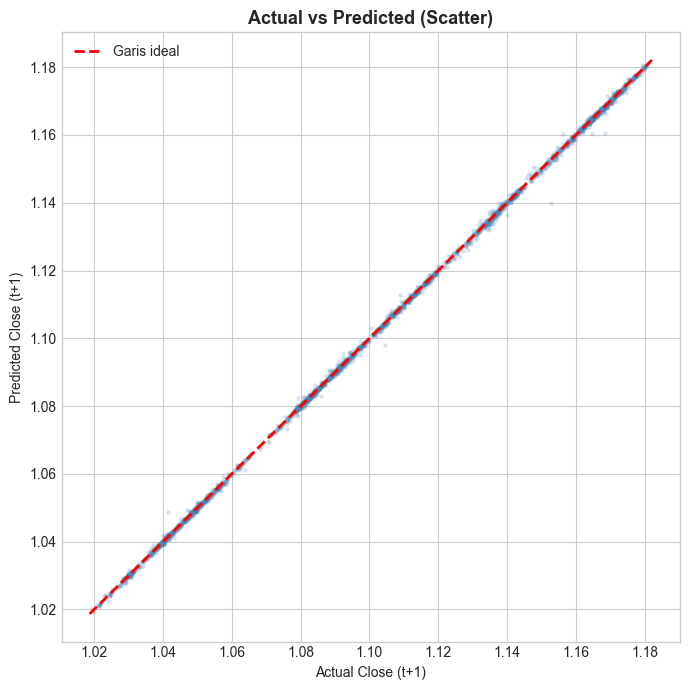

In [25]:
# Scatter Actual vs Predicted
idx_sample = np.random.choice(len(y_test_actual), min(3000, len(y_test_actual)), replace=False)

plt.figure(figsize=(7, 7))
plt.scatter(y_test_actual[idx_sample], y_pred_actual[idx_sample],
            alpha=0.15, s=5, color='steelblue')

lim_min = min(y_test_actual.min(), y_pred_actual.min())
lim_max = max(y_test_actual.max(), y_pred_actual.max())
plt.plot([lim_min, lim_max], [lim_min, lim_max], 'r--', linewidth=2, label='Garis ideal')

plt.title('Actual vs Predicted (Scatter)', fontsize=13, fontweight='bold')
plt.xlabel('Actual Close (t+1)')
plt.ylabel('Predicted Close (t+1)')
plt.legend()
plt.tight_layout()
plt.show()

---
## 10. Prediksi Manual (Input OHLC Baru)

In [26]:
def predict_close_next(open_price, high_price, low_price, close_price):
    """
    Prediksi Close t+1 berdasarkan input OHLC manual.

    Parameters:
        open_price  (float): Harga Open
        high_price  (float): Harga High
        low_price   (float): Harga Low
        close_price (float): Harga Close

    Returns:
        float: Prediksi harga Close periode berikutnya
    """
    input_data = pd.Series({
        'Open':  open_price,
        'High':  high_price,
        'Low':   low_price,
        'Close': close_price
    })

    # Normalisasi dengan skala training
    input_scaled = minmax_scale(input_data, X_min, X_max).values.reshape(1, -1)

    # Prediksi (scaled)
    pred_scaled = model.predict(input_scaled)[0]

    # Inverse transform
    pred_actual = minmax_inverse(pred_scaled, y_min, y_max)

    return float(np.clip(pred_actual, y_min, y_max))

OPEN_IN  = 1.0850
HIGH_IN  = 1.0865
LOW_IN   = 1.0840
CLOSE_IN = 1.0858

hasil = predict_close_next(OPEN_IN, HIGH_IN, LOW_IN, CLOSE_IN)

print("=" * 45)
print("    PREDIKSI CLOSE EUR/USD (t+1)")
print("=" * 45)
print(f"  Input:")
print(f"    Open  : {OPEN_IN:.5f}")
print(f"    High  : {HIGH_IN:.5f}")
print(f"    Low   : {LOW_IN:.5f}")
print(f"    Close : {CLOSE_IN:.5f}")
print(f"  ─────────────────────────────")
print(f"  Prediksi Close (t+1): {hasil:.5f}")
print("=" * 45)

    PREDIKSI CLOSE EUR/USD (t+1)
  Input:
    Open  : 1.08500
    High  : 1.08650
    Low   : 1.08400
    Close : 1.08580
  ─────────────────────────────
  Prediksi Close (t+1): 1.08532


In [27]:
import numpy as np
import pickle

# Definisi class wajib disertakan agar pickle dapat memuat objek dengan sempurna
class MultipleLinearRegression:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.lr = learning_rate
        self.n_iter = n_iterations
        self.weights = None
        self.bias = None
        self.loss_history = []

    def predict(self, X):
        return X @ self.weights + self.bias

def main_loop():
    try:
        with open('mlr_eurusd_model.pkl', 'rb') as f:
            data = pickle.load(f)
    except FileNotFoundError:
        print("Error: File 'mlr_eurusd_model.pkl' tidak ditemukan di folder ini.")
        return

    model = data['model']
    X_min = data['X_min']
    X_max = data['X_max']
    y_min = data['y_min']
    y_max = data['y_max']

    print("=" * 55)
    print("      PROGRAM INTERAKTIF PREDIKSI CLOSE EUR/USD (t+1)")
    print("=" * 55)
    print("Ketik 'keluar' untuk menghentikan program.\n")

    while True:
        user_input = input("Masukkan nilai Open High Low Close (pisahkan dengan spasi): ")

        if user_input.strip().lower() == 'keluar':
            print("Program selesai.")
            break

        try:
            inputs = [float(x) for x in user_input.split()]
            if len(inputs) != 4:
                print("Error: Harap masukkan tepat 4 angka (Open, High, Low, Close).\n")
                continue

            X_input = np.array(inputs)

            # proses MinMax Scaling
            X_scaled = (X_input - X_min) / (X_max - X_min)

            # Prediksi menggunakan model custom MLR
            pred_scaled = model.predict(X_scaled.reshape(1, -1))[0]

            # Inverse Transform kembali ke harga Forex riil
            pred_actual = pred_scaled * (y_max - y_min) + y_min
            pred_actual = np.clip(pred_actual, y_min, y_max)

            print("-" * 55)
            print(f" Input OHLC -> O: {inputs[0]:.5f} | H: {inputs[1]:.5f} | L: {inputs[2]:.5f} | C: {inputs[3]:.5f}")
            print(f" Hasil Prediksi Harga Close Periode Berikutnya: {pred_actual:.5f}")
            print("-" * 55 + "\n")

        except ValueError:
            print("Error: Input harus berupa angka desimal yang valid.\n")

if __name__ == "__main__":
    main_loop()

      PROGRAM INTERAKTIF PREDIKSI CLOSE EUR/USD (t+1)
Ketik 'keluar' untuk menghentikan program.

Program selesai.
